In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!unzip -qo "/content/drive/MyDrive/SolarPanelProject/SolarPanelsUltraYolo.zip" -d /content/
!pip install ultralytics
import os
import random
import shutil

random.seed(42)

# Create validation folders
os.makedirs('/content/images/val', exist_ok=True)
os.makedirs('/content/labels/val', exist_ok=True)

images = os.listdir('/content/images/train')
random.shuffle(images)

# Move 20% of images to validation
val_count = max(1, int(len(images) * 0.2))

for img in images[:val_count]:
    shutil.move(f'/content/images/train/{img}',
                f'/content/images/val/{img}')

    label = os.path.splitext(img)[0] + '.txt'
    shutil.move(f'/content/labels/train/{label}',
                f'/content/labels/val/{label}')

print("Done!")
print("Train images:", len(os.listdir('/content/images/train')))
print("Val images:", len(os.listdir('/content/images/val')))

Done!
Train images: 19
Val images: 4


In [ ]:
%%writefile /content/data.yaml
path: /content

train: images/train
val: images/val

names:
  0: solar panel

Overwriting /content/data.yaml


In [ ]:
!pip install --upgrade --force-reinstall ultralytics torch torchvision
import torch
import torchvision
from ultralytics import YOLO

model = YOLO("yolo11n-seg.pt")

results = model.train(
    data="/content/data.yaml",
    epochs=100,
    imgsz=1024,
    batch=4,
    project="solar_panel_segmentation",
    name="solar_seg"
)

  Using cached ultralytics-8.4.95-py3-none-any.whl.metadata (42 kB)
  Using cached torch-2.13.0-cp312-cp312-manylinux_2_28_x86_64.whl.metadata (38 kB)
  Using cached torchvision-0.28.0-cp312-cp312-manylinux_2_28_x86_64.whl.metadata (5.6 kB)
  Using cached numpy-2.5.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.0-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached opencv_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
  Using cached pillow-12.3.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyyaml-6.0.3-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (2.4 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached psutil-7.2.2-cp36-abi3-manylinux2010_x86_64.manylinux_2_12_x86_64.manylinux_2_28_x86_64.whl.metadata (22 kB)
  Using cached polars-1.42.1-p

Ultralytics 8.4.95 🚀 Python-3.12.13 torch-2.13.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=solar_seg-2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=Tr

In [ ]:
from ultralytics import YOLO

model640 = YOLO("/content/drive/MyDrive/SolarPanelProject/best.pt")
model1024 = YOLO("/content/drive/MyDrive/SolarPanelProject/solar_seg/solar_seg-2/weights/best.pt")



In [ ]:
results_640 = model640.predict(
    source="/content/drive/MyDrive/SolarPanelProject/SSD Dham.jpg",
    imgsz=640,
    save=True,
    name="prediction_640"
)
results_1024 = model1024.predict(
    source="/content/drive/MyDrive/SolarPanelProject/SSD Dham.jpg",
    imgsz=1024,
    save=True,
    name="prediction_1024"
)


image 1/1 /content/drive/MyDrive/SolarPanelProject/SSD Dham.jpg: 448x640 4 solar panels, 11.7ms
Speed: 4.0ms preprocess, 11.7ms inference, 1.9ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/segment/prediction_640-2

image 1/1 /content/drive/MyDrive/SolarPanelProject/SSD Dham.jpg: 704x1024 6 solar panels, 12.0ms
Speed: 6.7ms preprocess, 12.0ms inference, 2.3ms postprocess per image at shape (1, 3, 704, 1024)
Results saved to /content/runs/segment/prediction_1024


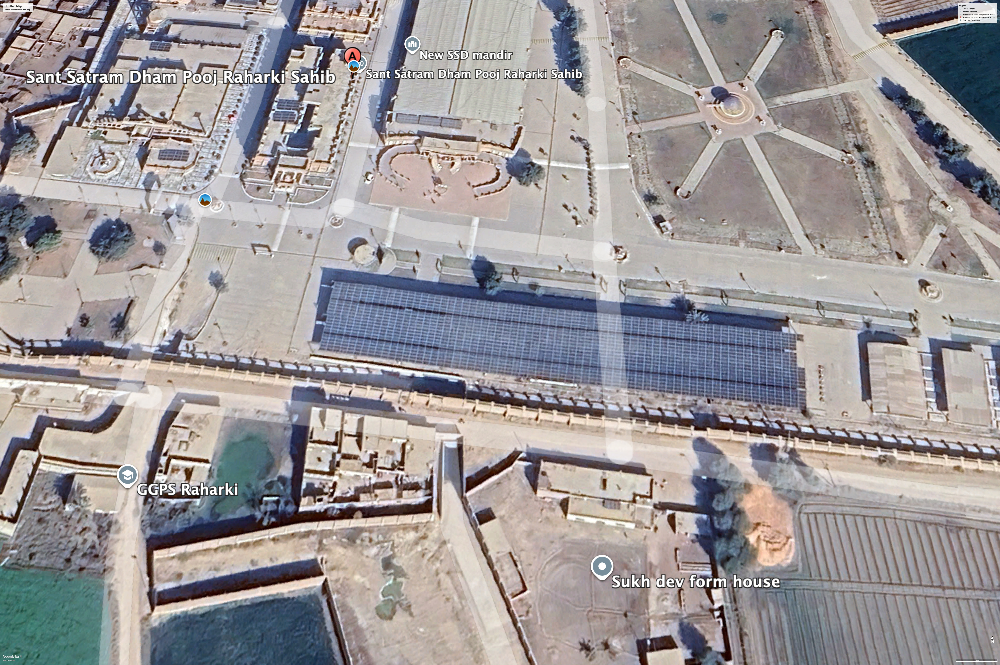

In [ ]:
from IPython.display import Image, display

display(Image("/content/drive/MyDrive/SolarPanelProject/SSD Dham.jpg"))

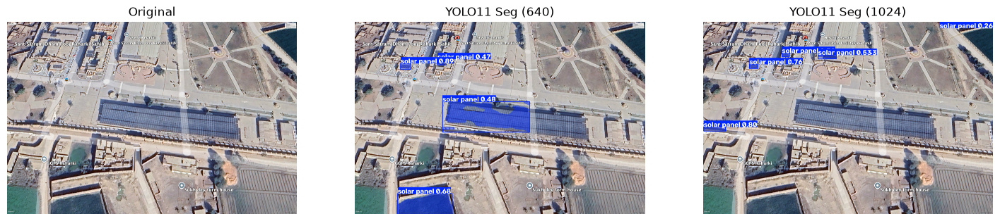

In [ ]:
import cv2
import matplotlib.pyplot as plt

original = cv2.cvtColor(cv2.imread("/content/drive/MyDrive/SolarPanelProject/SSD Dham.jpg"), cv2.COLOR_BGR2RGB)

pred640 = cv2.cvtColor(
    cv2.imread("/content/runs/segment/prediction_640/SSD Dham.jpg"),
    cv2.COLOR_BGR2RGB
)

pred1024 = cv2.cvtColor(
    cv2.imread("/content/runs/segment/prediction_1024/SSD Dham.jpg"),
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(18,6))

plt.subplot(1,3,1)
plt.imshow(original)
plt.title("Original")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(pred640)
plt.title("YOLO11 Seg (640)")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(pred1024)
plt.title("YOLO11 Seg (1024)")
plt.axis("off")

plt.show()